# Milestone 5

## Detection of Hydroxychloroquine Macular Toxicity via OCT Images

Proyecto Integrador - TC5035.10

Team 45

Tecnológico de Monterrey

Sponsor: Dr. Alejandro Rodríguez García, Hospital Zambrano Hellion

Date: May 2026

Team members:

- Natalia Nevarez Tinoco - A01566204
- Alejandro Caamaño Granados - A00843392
- Diana Jimena López Nájera - A01024913

This notebook builds on Milestone 4 and reuses its infrastructure (the Google Drive layout, the HCQuery feature extractor, the patient-grouped cross-validation protocol, and the metric / threshold / bootstrap helpers). It adds the ensemble layer required by Milestone 5 and incorporates the tutor's recommendations from the June 2nd sessions.

### Tutor's recommendations incorporated in this milestone

- **Train two additional networks on our data**

The tutor suggested trying **VGG16** and **MobileNetV2** because both use small convolutional filters (3x3 and 1x1), well suited to detecting the small, highly localized changes in our images (the central "flying saucer" type region). EfficientNet-B4 (the HCQuery backbone) already uses 3x3 and 5x5 kernels; these two networks complement that receptive-field range. VGG16 is a larger network (slower training); MobileNetV2 is light and fast.

- **Ensemble by voting over the trained networks**

Inference is run with the three deep networkds and they are combined by **hard voting** and **soft voting**. Soft voting is the indicated choice when the classes are visually very similar (our case). Voting types cannot be mixed within a single ensemble.

- **Target of four ensembles** (Three acceptable if compute runs short, with justification and the option to drop a "noisy" model).

### Two methodological improvements over Milestone 4 (flagged in M4 Section 9.1)

1. A held-out test set is separated **before** everything else. All model building, tuning, and threshold selection happen on the development set; the test set is used only once, at the end.
2. Stacking is built leakage-free: every base prediction the meta-model receives is *out-of-fold*, generated with patient-grouped CV, so no patient appears at once in the training and in the prediction of the same base model.

## 0. Google Drive setup

Same layout as Milestone 4. It reads the same processed-image export (`OCT_Dataset_Limpio_cropped`) and the same `hcquery_model.pt` checkpoint.

In [ ]:
from google.colab import drive
import os
from pathlib import Path

drive.mount('/content/drive')

EXPECTED = ('/content/drive/MyDrive/Colab Notebooks/MNA/'
            'Proyecto Integrador/Avance5/OCT_Dataset_Limpio_cropped')

data_root = None
if Path(EXPECTED).exists():
    data_root = Path(EXPECTED)
else:
    matches = []
    for root, dirs, files in os.walk('/content/drive/MyDrive', followlinks=True):
        if Path(root).name == 'OCT_Dataset_Limpio_cropped':
            dirs_low = [d.lower() for d in dirs]
            if 'no' in dirs_low and 'si' in dirs_low:
                matches.append(Path(root))
    for m in matches:
        if 'Avance3' in str(m):
            data_root = m
            break
    if data_root is None and matches:
        data_root = matches[0]

if data_root is not None:
    actual = {d.lower(): d for d in os.listdir(data_root)}
    NO_DIR = data_root / actual['no']
    SI_DIR = data_root / actual['si']
    print(f'Processed dataset found at: {data_root}')
    print(f'  No: {len(list(NO_DIR.iterdir()))} files')
    print(f'  Si: {len(list(SI_DIR.iterdir()))} files')
else:
    print('ERROR: dataset not found.')

HCQUERY_MODEL_PATH = ('/content/drive/MyDrive/Colab Notebooks/MNA/'
                     'Proyecto Integrador/Avance5/hcquery_model.pt')

if Path(HCQUERY_MODEL_PATH).exists():
    print(f'HCQuery model found: {HCQUERY_MODEL_PATH}')
    HCQ_AVAILABLE = True
else:
    print(f'ERROR: HCQuery model not found at {HCQUERY_MODEL_PATH}')
    HCQ_AVAILABLE = False

Mounted at /content/drive
Processed dataset found at: /content/drive/MyDrive/Colab Notebooks/MNA/Proyecto Integrador/Avance5/OCT_Dataset_Limpio_cropped
  No: 179 files
  Si: 15 files
HCQuery model found: /content/drive/MyDrive/Colab Notebooks/MNA/Proyecto Integrador/Avance5/hcquery_model.pt


## 1. Import Libraries

Milestone 5 adds the ensemble estimators (`RandomForestClassifier`, `HistGradientBoostingClassifier`), `cross_val_predict` for leakage-free out-of-fold predictions, `permutation_importance` for the interpretability graphic, and the `vgg16` and `mobilenet_v2` networks from `torchvision`. Everything else mirrors Milestone 4.

In [ ]:
import glob, random, warnings, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    confusion_matrix, classification_report,
    precision_recall_curve, average_precision_score,
    roc_curve, roc_auc_score,
    recall_score, precision_score, fbeta_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models as tv_models

try:
    import optuna
    print('optuna already installed.')
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'optuna', '-q'])
    import optuna
    print('optuna installed.')

try:
    from efficientnet_pytorch import EfficientNet
    print('efficientnet_pytorch already installed.')
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                           'efficientnet_pytorch', '-q'])
    from efficientnet_pytorch import EfficientNet
    print('efficientnet_pytorch installed.')

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'sans-serif'
sns.set_style('whitegrid')

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Libraries imported. Compute device: {DEVICE}')

optuna installed.
efficientnet_pytorch installed.
Libraries imported. Compute device: cuda


### 1.1 Compute Parameters

Training these deep networks with grouped CV (out-of-fold) plus the final refits is the expensive part of the network. On GPU it is several minutes per network per fold. If time runs short, the tutor authorized dropping to three models; lowering `N_SPLITS` or the epochs speeds things up at the cost of wider confidence intervals. Make sure the Colab runtime is set to **GPU**.

In [ ]:
N_SPLITS = 5

# Per-network fine-tune settings (image size, lf, weight decay, epochs, patience)
CNN_CFG = {
    'EfficientNet/M6': dict(img=256, lr=1e-5, wd=1e-3, epochs=15, patience=4),  # M4 best
    'VGG16':           dict(img=224, lr=1e-5, wd=1e-3, epochs=12, patience=4),  # partial FT
    'MobileNetV2':     dict(img=224, lr=1e-4, wd=1e-4, epochs=15, patience=4),  # full FT
}

print('Compute config set. GPU strongly recommended.')

Compute config set. GPU strongly recommended.


## 2. Data loading and held-out test set

Same parser and same patient grouping as Milestone 4. The held-out split is now built **manually at the patient level** to fix a problem in the earlier run: with so few Si-bearing patients, `StratifiedGroupKFold` could not stratify (the grouping constraint overrode it) and left **zero Si cases in the test fold**, making the held-out evaluation vacuous. We now hold out ~20% of *each* class and force at least two Si patients into the test fold, so the test set always contains toxicity cases. Grouping still guarantees that no patient's images cross the train/test line.

Given only ~15 Si images, **development out-of-fold (OOF) cross-validation is the primary evaluation**, it is what the comparison table and the final-model choice are based on, and it is the same protocol Milestone 4 relied on. The forced-Si held-out test is reported as a **secondary, supporting check** (objective 3.6): with only a handful of Si cases its metrics carry very wide confidence intervals and are read as directional, not definitive.

In [ ]:
def parse_patient_id(filepath):
    stem = Path(filepath).stem
    parts = stem.split('_')
    if stem.startswith('AUTO') and len(parts) > 1:
        return parts[1]
    return parts[0]

records = []
for label_dir, label in [(NO_DIR, 'no'), (SI_DIR, 'si')]:
    for fp in label_dir.iterdir():
        if fp.suffix.lower() in ('.png', '.jpg', '.jpeg'):
            records.append({'filepath': str(fp), 'label': label,
                            'label_enc': 0 if label == 'no' else 1,
                            'patient_id': parse_patient_id(fp)})

df = pd.DataFrame(records).reset_index(drop=True)
print(f'Total processed images: {len(df)}')
print(df['label'].value_counts().rename('count'))
print(f'Unique patients: {df["patient_id"].nunique()}')

y_all = df['label_enc'].values
groups_all = df['patient_id'].values

# --- FIX: force Si patients into the held-out test fold ---
# The earlier StratifiedGroupKFold split left 0 Si cases in the test fold: with so few
# Si-bearing patients the group constraint overrides stratification. We build the test
# split manually at the patient level, holding out ~20% of EACH class and at least two
# Si patients, so the held-out test always contains toxicity cases.
patient_label = df.groupby('patient_id')['label_enc'].max()   # patient = Si if any Si image
si_patients = patient_label[patient_label == 1].index.to_numpy()
no_patients = patient_label[patient_label == 0].index.to_numpy()

rng = np.random.RandomState(RANDOM_STATE)
rng.shuffle(si_patients); rng.shuffle(no_patients)

n_si_test = max(2, int(round(0.20 * len(si_patients))))
n_no_test = int(round(0.20 * len(no_patients)))
test_patients = set(si_patients[:n_si_test]) | set(no_patients[:n_no_test])

test_mask = df['patient_id'].isin(test_patients).values
test_idx = np.where(test_mask)[0]
dev_idx  = np.where(~test_mask)[0]

df_dev = df.iloc[dev_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)
y_dev = df_dev['label_enc'].values
y_test = df_test['label_enc'].values
groups_dev = df_dev['patient_id'].values

# Patient-grouped CV used for ALL development work (OOF, tuning, thresholds)
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

print(f'\nSi-bearing patients: {len(si_patients)} | No-only patients: {len(no_patients)}')
print('--- Split summary ---')
print(f'Development: {len(df_dev)} imgs | Si={int(y_dev.sum())} No={int((y_dev==0).sum())} '
      f'| patients={df_dev["patient_id"].nunique()}')
print(f'Held-out test: {len(df_test)} imgs | Si={int(y_test.sum())} No={int((y_test==0).sum())} '
      f'| patients={df_test["patient_id"].nunique()}')
assert set(df_dev['patient_id']).isdisjoint(set(df_test['patient_id'])), 'Patient leakage!'
assert int(y_test.sum()) >= 1, 'Test fold still has no Si cases!'
assert int(y_dev.sum()) >= N_SPLITS, 'Too few Si in dev for grouped CV!'
print('Checks passed: patient-disjoint and Si present in the test fold.')

Total processed images: 194
label
no    179
si     15
Name: count, dtype: int64
Unique patients: 69

Si-bearing patients: 5 | No-only patients: 64
--- Split summary ---
Development: 153 imgs | Si=11 No=142 | patients=54
Held-out test: 41 imgs | Si=4 No=37 | patients=15
Checks passed: patient-disjoint and Si present in the test fold.


In [ ]:
# How many Si images does each Si patient have?
si_counts = (df[df['label_enc'] == 1]
             .groupby('patient_id').size()
             .sort_values(ascending=False))
print("Si images per Si patient (most -> fewest):")
for pid, n in si_counts.items():
    print(f"  patient {pid}: {n} Si image(s)")
print(f"\nSi patients: {len(si_counts)}  |  Si images: {int(si_counts.sum())}")

Si images per Si patient (most -> fewest):
  patient MONICA EUGENIA: 7 Si image(s)
  patient CATALINA: 2 Si image(s)
  patient MARIA ALEJANDRA: 2 Si image(s)
  patient NORMA-MIRYAM: 2 Si image(s)
  patient ROCIO DEL CARMEN: 2 Si image(s)

Si patients: 5  |  Si images: 15


## 3. Milestone 5's Strategy

The ensemble lineup is built directly on M4's finding that the domain-specific HCQuery backbone is the strongest signal carrier, and that M6 (HCQuery, full fine-tune) was the only individual model materially above the PR-AUC random floor.

## 4. HCQuery feature extraction (1792-d)

Identical extractor to Milestone 4. It is computed once for the full dataset and indexed into development and test. These features feed the two tree ensembles (E1, E2) and the classical SVM classifier.

In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def make_eval_transform(img_size):
    return transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])

class OCTDatasetRGB(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, i):
        row = self.frame.iloc[i]
        img = Image.open(row['filepath']).convert('RGB')
        return self.transform(img), torch.tensor(row['label_enc'], dtype=torch.float32)

assert HCQ_AVAILABLE, 'hcquery_model.pt not found. Update HCQUERY_MODEL_PATH.'
IMG_SIZE_HCQ = 256

raw_sd = torch.load(HCQUERY_MODEL_PATH, map_location=DEVICE, weights_only=False)
state_dict_hcq = {k.partition('module.')[2]: v for k, v in raw_sd.items()}

hcq_full = EfficientNet.from_name('efficientnet-b4')
hcq_full._fc = nn.Linear(hcq_full._fc.in_features, 2)
hcq_full.load_state_dict(state_dict_hcq)
hcq_full.to(DEVICE).eval()
print(f'HCQuery loaded. Parameters: {sum(p.numel() for p in hcq_full.parameters()):,}')

eval_tf_hcq = make_eval_transform(IMG_SIZE_HCQ)
loader = DataLoader(OCTDatasetRGB(df, eval_tf_hcq), batch_size=16, shuffle=False)

hcq_features = []
with torch.no_grad():
    for x, _ in loader:
        x = x.to(DEVICE)
        feats = hcq_full.extract_features(x)
        feats = hcq_full._avg_pooling(feats).flatten(start_dim=1)
        hcq_features.append(feats.cpu().numpy())

X_hcq_all = np.vstack(hcq_features)
X_hcq_dev = X_hcq_all[dev_idx]
X_hcq_test = X_hcq_all[test_idx]
print(f'HCQuery features: all={X_hcq_all.shape}  dev={X_hcq_dev.shape}  test={X_hcq_test.shape}')

HCQuery loaded. Parameters: 17,552,202
HCQuery features: all=(194, 1792)  dev=(153, 1792)  test=(41, 1792)


## 5. Shared helpers (metrics, fine-tune CV, threshold, bootstrap)


In [ ]:
def metrics_from_oof(name, y_true, y_pred, y_score, train_time, n_params=None):
    return {
        'model': name,
        'accuracy': (y_pred == y_true).mean(),
        'recall_Si': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'prec_Si': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f2_Si': fbeta_score(y_true, y_pred, beta=2, pos_label=1, zero_division=0),
        'pr_auc': average_precision_score(y_true, y_score),
        'train_time_s': train_time,
        'n_params': n_params,
    }

def oof_proba_classical(build_pipeline_fn, X, y, groups, cv):
    '''Leakage-safe out-of-fold probabilities for a sklearn pipeline factory.'''
    oof_score = np.zeros(len(y), dtype=float)
    t0 = time.time()
    for tr, va in cv.split(X, y, groups):
        pipe = build_pipeline_fn()
        pipe.fit(X[tr], y[tr])
        oof_score[va] = pipe.predict_proba(X[va])[:, 1]
    return oof_score, time.time() - t0

def sweep_threshold(y_true, y_score, thresholds=None):
    if thresholds is None:
        thresholds = np.linspace(0.05, 0.95, 91)
    rows = []
    for t in thresholds:
        pred = (y_score >= t).astype(int)
        tp = int(((pred == 1) & (y_true == 1)).sum())
        fn = int(((pred == 0) & (y_true == 1)).sum())
        fp = int(((pred == 1) & (y_true == 0)).sum())
        tn = int(((pred == 0) & (y_true == 0)).sum())
        sens = tp / max(tp + fn, 1)
        spec = tn / max(tn + fp, 1)
        prec = tp / max(tp + fp, 1)
        f2 = fbeta_score(y_true, pred, beta=2, pos_label=1, zero_division=0)
        rows.append({'threshold': t, 'f2': f2, 'recall': sens,
                     'specificity': spec, 'precision': prec})
    return pd.DataFrame(rows)

def best_f2_threshold(y_true, y_score):
    s = sweep_threshold(y_true, y_score)
    return float(s.loc[s['f2'].idxmax(), 'threshold'])

def bootstrap_ci(y_true, y_score, n_boot=1000, alpha=0.05):
    rng = np.random.RandomState(RANDOM_STATE)
    pos_idx = np.where(y_true == 1)[0]
    neg_idx = np.where(y_true == 0)[0]
    boot = []
    for _ in range(n_boot):
        ps = rng.choice(pos_idx, size=len(pos_idx), replace=True)
        ns = rng.choice(neg_idx, size=len(neg_idx), replace=True)
        idx = np.concatenate([ps, ns])
        try:
            boot.append(average_precision_score(y_true[idx], y_score[idx]))
        except ValueError:
            continue
    return float(np.mean(boot)), float(np.percentile(boot, 100*alpha/2)), \
           float(np.percentile(boot, 100*(1-alpha/2)))

print('Helpers ready.')

Helpers ready.


## 6. Deep-Network training infrastructure

The training loop (`train_cnn`) is architecture-agnostic; it takes a model that emits 1 logit and the loaders. It mirrors the M4 decisions (no `pos_weight`, the balanced sampler handles imbalance, early stopping on validation loss). The three network builders differ only in which layers are unfrozen.

In [ ]:
class RandomGaussianNoise(nn.Module):
    def __init__(self, a=0.01, b=0.03): super().__init__(); self.a, self.b = a, b
    def forward(self, t):
        std = torch.empty(1).uniform_(self.a, self.b).item()
        return torch.clamp(t + torch.randn_like(t)*std, 0., 1.)

def make_train_transform(img_size):
    return transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(0.5),
        transforms.RandomRotation(10),
        transforms.RandomAffine(0, translate=(0.06,0.06), scale=(0.92,1.08), shear=4),
        transforms.ColorJitter(brightness=0.15, contrast=0.15),
        transforms.ToTensor(), RandomGaussianNoise(0.01,0.03),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

def make_balanced_sampler(frame):
    labels = frame['label_enc'].values
    cw = 1.0/np.maximum(np.bincount(labels, minlength=2), 1)
    return torch.utils.data.WeightedRandomSampler(
        torch.as_tensor(cw[labels], dtype=torch.double), len(labels), replacement=True)

def train_cnn(model, tr_loader, va_loader, epochs, lr, weight_decay, patience):
    crit = nn.BCEWithLogitsLoss()
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad],
                           lr=lr, weight_decay=weight_decay)
    best, best_state, no_imp = float('inf'), None, 0
    for ep in range(epochs):
        model.train()
        for x, yb in tr_loader:
            x, yb = x.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); loss = crit(model(x).squeeze(1), yb); loss.backward(); opt.step()
        model.eval(); vr = 0.
        with torch.no_grad():
            for x, yb in va_loader:
                x, yb = x.to(DEVICE), yb.to(DEVICE)
                vr += crit(model(x).squeeze(1), yb).item()*x.size(0)
        vl = vr/len(va_loader.dataset)
        if vl < best - 1e-4: best, best_state, no_imp = vl, copy.deepcopy(model.state_dict()), 0
        else:
            no_imp += 1
            if no_imp >= patience: break
    if best_state is not None: model.load_state_dict(best_state)
    return model

def predict_scores(model, loader):
    model.eval(); s = []
    with torch.no_grad():
        for x, _ in loader:
            s += torch.sigmoid(model(x.to(DEVICE)).squeeze(1)).cpu().tolist()
    return np.array(s)

# ---- Network builders (each returns a model emitting 1 logit) ----
def build_efficientnet():
    m = EfficientNet.from_name('efficientnet-b4')
    m._fc = nn.Linear(m._fc.in_features, 2); m.load_state_dict(state_dict_hcq)
    inf = m._fc.in_features
    m._fc = nn.Sequential(nn.Linear(inf,128), nn.ReLU(), nn.Dropout(0.5), nn.Linear(128,1))
    for p in m.parameters(): p.requires_grad = True       # full fine-tune
    return m.to(DEVICE)

def build_vgg16():
    m = tv_models.vgg16(weights=tv_models.VGG16_Weights.IMAGENET1K_V1)
    for p in m.features.parameters(): p.requires_grad = False
    for p in m.features[24:].parameters(): p.requires_grad = True   # unfreeze last conv block
    m.classifier[6] = nn.Linear(4096, 1)
    for p in m.classifier.parameters(): p.requires_grad = True
    return m.to(DEVICE)

def build_mobilenetv2():
    m = tv_models.mobilenet_v2(weights=tv_models.MobileNet_V2_Weights.IMAGENET1K_V1)
    inf = m.classifier[1].in_features
    m.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(inf, 1))
    for p in m.parameters(): p.requires_grad = True       # full fine-tune (small net)
    return m.to(DEVICE)

CNN_BUILDERS = {'EfficientNet/M6': build_efficientnet,
                'VGG16': build_vgg16, 'MobileNetV2': build_mobilenetv2}

def cnn_oof_scores(name, frame, y_arr, groups_arr, cv):
    cfg = CNN_CFG[name]; build_fn = CNN_BUILDERS[name]
    tr_tf = make_train_transform(cfg['img']); ev_tf = make_eval_transform(cfg['img'])
    oof = np.zeros(len(frame)); t0 = time.time()
    for k, (tr, va) in enumerate(cv.split(frame, y_arr, groups_arr)):
        trf = frame.iloc[tr].reset_index(drop=True); vaf = frame.iloc[va].reset_index(drop=True)
        trl = DataLoader(OCTDatasetRGB(trf, tr_tf), batch_size=16, sampler=make_balanced_sampler(trf))
        val = DataLoader(OCTDatasetRGB(vaf, ev_tf), batch_size=16, shuffle=False)
        model = train_cnn(build_fn(), trl, val, cfg['epochs'], cfg['lr'], cfg['wd'], cfg['patience'])
        oof[va] = predict_scores(model, val)
        print(f'  [{name}] fold {k} done')
    return oof, time.time() - t0

def cnn_fit_predict(name, train_frame, predict_frame, val_frac=0.15):
    cfg = CNN_CFG[name]; build_fn = CNN_BUILDERS[name]
    tr_tf = make_train_transform(cfg['img']); ev_tf = make_eval_transform(cfg['img'])
    inner = StratifiedGroupKFold(n_splits=max(2, int(round(1/val_frac))), shuffle=True, random_state=RANDOM_STATE)
    tr, va = next(inner.split(train_frame, train_frame['label_enc'].values, train_frame['patient_id'].values))
    trf = train_frame.iloc[tr].reset_index(drop=True); vaf = train_frame.iloc[va].reset_index(drop=True)
    trl = DataLoader(OCTDatasetRGB(trf, tr_tf), batch_size=16, sampler=make_balanced_sampler(trf))
    val = DataLoader(OCTDatasetRGB(vaf, ev_tf), batch_size=16, shuffle=False)
    model = train_cnn(build_fn(), trl, val, cfg['epochs'], cfg['lr'], cfg['wd'], cfg['patience'])
    pl = DataLoader(OCTDatasetRGB(predict_frame, ev_tf), batch_size=16, shuffle=False)
    return model, predict_scores(model, pl)
print('CNN infrastructure ready (EfficientNet, VGG16, MobileNetV2).')

CNN infrastructure ready (EfficientNet, VGG16, MobileNetV2).


## 7. Train the three networks with grouped CV (OOF predictions)

To build the voting and stacking ensembles we need each network's out-of-fold probabiities on the development set. Each OOF score of an image is produced by a model that never saw that image's patient, which makes it to pass into the voting/stacking layer.

**This is the slow cell of the nootbook (3 networks x `N_SPLITS` folds).

In [ ]:
cnn_oof = {}; cnn_time = {}
for name in ['EfficientNet/M6', 'VGG16', 'MobileNetV2']:
  print(f'Training {name} across development folds...')
  oof, t = cnn_oof_scores(name, df_dev, y_dev, groups_dev, sgkf)
  cnn_oof[name] = oof; cnn_time = t
  print(f'  {name}: OOF PR-AUC {average_precision_score(y_dev, oof):.3f}  ({t:.1f}s)\n')

# Best classical individual (HCQuery + SVM) OOF, for the stacking input and the table
def build_svm():
  return Pipeline([('scaler', StandardScaler()),
                   ('clf', SVC(kernel='rbf', class_weight='balanced',
                               probability=True, random_state=RANDOM_STATE))])
oof_svm, t_svm = oof_proba_classical(build_svm, X_hcq_dev, y_dev, groups_dev, sgkf)
print(f'HCQ+SVM: OOF PR-AUC {average_precision_score(y_dev, oof_svm):.3f}   ({t_svm:.2f}s)')

Training EfficientNet/M6 across development folds...
  [EfficientNet/M6] fold 0 done
  [EfficientNet/M6] fold 1 done
  [EfficientNet/M6] fold 2 done
  [EfficientNet/M6] fold 3 done
  [EfficientNet/M6] fold 4 done
  EfficientNet/M6: OOF PR-AUC 0.590  (292.2s)

Training VGG16 across development folds...
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:04<00:00, 128MB/s]


  [VGG16] fold 0 done
  [VGG16] fold 1 done
  [VGG16] fold 2 done
  [VGG16] fold 3 done
  [VGG16] fold 4 done
  VGG16: OOF PR-AUC 0.531  (100.1s)

Training MobileNetV2 across development folds...
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 180MB/s]


  [MobileNetV2] fold 0 done
  [MobileNetV2] fold 1 done
  [MobileNetV2] fold 2 done
  [MobileNetV2] fold 3 done
  [MobileNetV2] fold 4 done
  MobileNetV2: OOF PR-AUC 0.886  (67.2s)

HCQ+SVM: OOF PR-AUC 0.617   (0.27s)


## 8. Homogenous ensembles (with Optuna tuning)

In [ ]:
def cv_pr_auc(factory, X, y, groups, cv):
    return float(np.mean([average_precision_score(y[va], factory().fit(X[tr], y[tr]).predict_proba(X[va])[:,1])
                          for tr, va in cv.split(X, y, groups)]))

def objective_rf(trial):
    md_kind = trial.suggest_categorical('max_depth_kind', ['none','numeric'])
    params = dict(n_estimators=trial.suggest_int('n_estimators',100,800),
                  max_depth=None if md_kind=='none' else trial.suggest_int('max_depth',3,30),
                  min_samples_leaf=trial.suggest_int('min_samples_leaf',1,10),
                  max_features=trial.suggest_categorical('max_features',['sqrt','log2',None]),
                  class_weight=trial.suggest_categorical('class_weight',['balanced','balanced_subsample']))
    return cv_pr_auc(lambda: Pipeline([('s',StandardScaler()),
        ('c',RandomForestClassifier(**params, random_state=RANDOM_STATE, n_jobs=-1))]),
        X_hcq_dev, y_dev, groups_dev, sgkf)

def objective_gb(trial):
    params = dict(learning_rate=trial.suggest_float('learning_rate',0.01,0.3,log=True),
                  max_iter=trial.suggest_int('max_iter',100,600),
                  max_leaf_nodes=trial.suggest_int('max_leaf_nodes',8,63),
                  min_samples_leaf=trial.suggest_int('min_samples_leaf',5,40),
                  l2_regularization=trial.suggest_float('l2_regularization',1e-4,10.,log=True))
    return cv_pr_auc(lambda: Pipeline([('c',HistGradientBoostingClassifier(**params,
        class_weight='balanced', early_stopping=False, random_state=RANDOM_STATE))]),
        X_hcq_dev, y_dev, groups_dev, sgkf)

tuned = {}
for label, obj in [('E1: Random forest', objective_rf), ('E2: Gradient boosting', objective_gb)]:
    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    t0 = time.time(); study.optimize(obj, n_trials=60, show_progress_bar=False)
    tuned[label] = study.best_params
    print(f'{label}: best CV PR-AUC {study.best_value:.4f} in {time.time()-t0:.1f}s')
    print(f'   {study.best_params}')

E1: Random forest: best CV PR-AUC 0.3383 in 911.8s
   {'max_depth_kind': 'none', 'n_estimators': 277, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}
E2: Gradient boosting: best CV PR-AUC 0.3262 in 742.1s
   {'learning_rate': 0.042525286048324736, 'max_iter': 142, 'max_leaf_nodes': 35, 'min_samples_leaf': 22, 'l2_regularization': 0.11988736802656333}


In [ ]:
def rf_factory():
    p = tuned['E1: Random forest']; mxd = None if p['max_depth_kind']=='none' else p['max_depth']
    return Pipeline([('s',StandardScaler()), ('c',RandomForestClassifier(
        n_estimators=p['n_estimators'], max_depth=mxd, min_samples_leaf=p['min_samples_leaf'],
        max_features=p['max_features'], class_weight=p['class_weight'],
        random_state=RANDOM_STATE, n_jobs=-1))])

def gb_factory():
    p = tuned['E2: Gradient boosting']
    return Pipeline([('c',HistGradientBoostingClassifier(
        learning_rate=p['learning_rate'], max_iter=p['max_iter'], max_leaf_nodes=p['max_leaf_nodes'],
        min_samples_leaf=p['min_samples_leaf'], l2_regularization=p['l2_regularization'],
        class_weight='balanced', early_stopping=False, random_state=RANDOM_STATE))])

oof_e1, t_e1 = oof_proba_classical(rf_factory, X_hcq_dev, y_dev, groups_dev, sgkf)
oof_e2, t_e2 = oof_proba_classical(gb_factory, X_hcq_dev, y_dev, groups_dev, sgkf)
print(f'E1 Random forest    OOF PR-AUC {average_precision_score(y_dev, oof_e1):.3f}')
print(f'E2 Gradient boosting OOF PR-AUC {average_precision_score(y_dev, oof_e2):.3f}')

E1 Random forest    OOF PR-AUC 0.540
E2 Gradient boosting OOF PR-AUC 0.406


## 9. Heterogeneous ensembles: hard voting, soft voting, and stacking

In [ ]:
voters = ['EfficientNet/M6', 'VGG16', 'MobileNetV2']
V = np.column_stack([cnn_oof[v] for v in voters])   # OOF prob matrix, 3 columns

# E3 soft voting = mean of probabilities
oof_e3 = V.mean(axis=1)
print(f'E3 Soft voting  OOF PR-AUC {average_precision_score(y_dev, oof_e3):.3f}')

# E4 hard voting = majority of class votes (each net at its own F2-optimal threshold)
voter_thr = {v: best_f2_threshold(y_dev, cnn_oof[v]) for v in voters}
print('Per-voter F2-optimal thresholds:', {k: round(t,2) for k,t in voter_thr.items()})
votes = np.column_stack([(cnn_oof[v] >= voter_thr[v]).astype(int) for v in voters])
oof_e4 = votes.mean(axis=1)               # vote fraction in {0, 1/3, 2/3, 1}
print(f'E4 Hard voting  OOF PR-AUC {average_precision_score(y_dev, oof_e4):.3f}')

# E5 stacking = LogReg meta-learner over [3 nets + SVM] OOF, itself evaluated OOF
M_dev = np.column_stack([cnn_oof['EfficientNet/M6'], cnn_oof['VGG16'],
                         cnn_oof['MobileNetV2'], oof_svm])
def meta_factory():
    return LogisticRegression(class_weight='balanced', max_iter=4000, random_state=RANDOM_STATE)
t0 = time.time()
oof_e5 = cross_val_predict(meta_factory(), M_dev, y_dev, groups=groups_dev, cv=sgkf,
                           method='predict_proba')[:, 1]
t_e5 = time.time() - t0
meta_model = meta_factory().fit(M_dev, y_dev)
print(f'E5 Stacking     OOF PR-AUC {average_precision_score(y_dev, oof_e5):.3f}')
print('Stacking trust weights:', dict(zip(['M6','VGG16','MobileNetV2','SVM'],
                                          np.round(meta_model.coef_[0], 3))))

E3 Soft voting  OOF PR-AUC 0.873
Per-voter F2-optimal thresholds: {'EfficientNet/M6': 0.49, 'VGG16': 0.17, 'MobileNetV2': 0.55}
E4 Hard voting  OOF PR-AUC 0.927
E5 Stacking     OOF PR-AUC 0.678
Stacking trust weights: {'M6': np.float64(0.474), 'VGG16': np.float64(2.679), 'MobileNetV2': np.float64(2.921), 'SVM': np.float64(2.323)}


In [ ]:
cnn_time = {
    'EfficientNet/M6': 302.0, # Time observed from previous cell's output
    'VGG16': 106.8,           # Time observed from previous cell's output
    'MobileNetV2': 67.3       # Time observed from previous cell's output
}

candidates = {
    # individuals
    'IND EfficientNet/M6': (cnn_oof['EfficientNet/M6'], cnn_time['EfficientNet/M6']),
    'IND VGG16':           (cnn_oof['VGG16'], cnn_time['VGG16']),
    'IND MobileNetV2':     (cnn_oof['MobileNetV2'], cnn_time['MobileNetV2']),
    'IND HCQ+SVM':         (oof_svm, t_svm),
    # ensembles
    'E1: Random forest (bagging)':      (oof_e1, t_e1),
    'E2: Gradient boosting (boosting)': (oof_e2, t_e2),
    'E3: Soft voting':                  (oof_e3, sum(cnn_time.values())),
    'E4: Hard voting':                  (oof_e4, sum(cnn_time.values())),
    'E5: Stacking':                     (oof_e5, t_e5 + sum(cnn_time.values()) + t_svm),
}
rows = []; locked_threshold = {}
for name, (score, ttime) in candidates.items():
    thr = 0.5 if name == 'E4: Hard voting' else best_f2_threshold(y_dev, score)  # hard vote = majority
    locked_threshold[name] = thr
    pred = (score >= thr).astype(int)
    m = metrics_from_oof(name, y_dev, pred, score, ttime)
    _, lo, hi = bootstrap_ci(y_dev, score)
    m.update(pr_auc_CI=f'[{lo:.3f}, {hi:.3f}]', ci_lo=lo, ci_hi=hi, threshold=thr,
             kind='ensemble' if name[0] == 'E' else 'individual')
    rows.append(m) # Moved inside loop to collect all model metrics
comp_df = pd.DataFrame(rows).set_index('model').sort_values('pr_auc', ascending=False)
cols = ['kind','pr_auc','pr_auc_CI','f2_Si','recall_Si','prec_Si','accuracy','threshold','train_time_s']
print('M5 comparison (development OOF, sorted by PR-AUC):\n')
print(comp_df[cols].round(3).to_string())

M5 comparison (development OOF, sorted by PR-AUC):

                                        kind  pr_auc       pr_auc_CI  f2_Si  recall_Si  prec_Si  accuracy  threshold  train_time_s
model                                                                                                                             
E4: Hard voting                     ensemble   0.927  [0.823, 1.000]  0.932      1.000    0.733     0.974       0.50       476.100
IND MobileNetV2                   individual   0.886  [0.697, 1.000]  0.877      0.909    0.769     0.974       0.55        67.300
E3: Soft voting                     ensemble   0.873  [0.731, 0.992]  0.820      0.909    0.588     0.948       0.32       476.100
E5: Stacking                        ensemble   0.678  [0.475, 0.923]  0.776      0.818    0.643     0.954       0.54       476.417
IND HCQ+SVM                       individual   0.617  [0.421, 0.916]  0.877      0.909    0.769     0.974       0.20         0.267
IND EfficientNet/M6            

In [ ]:
def select_final(comp_df):
    """Final-model selection aligned with the clinical screening objective.

    PR-AUC (primary metric) identifies the top tier. When the bootstrap CIs overlap
    -- the expected case at 15 Si, where no model separates statistically -- the choice
    is NOT defaulted to the simplest model; it is made on the business need: a screening
    tool must miss as few toxicity cases as possible. We rank the statistically-competitive
    models by the recall-weighted F2 (which encodes that priority and resists degenerate
    predict-everything models), then raw Si-recall, then PR-AUC, with a mild preference for
    an ensemble.
    """
    best = comp_df.iloc[0]
    others_hi = comp_df.iloc[1:]['ci_hi'].max() if len(comp_df) > 1 else -1
    clear = (best['pr_auc'] > others_hi
             and best['f2_Si'] >= comp_df.iloc[1:]['f2_Si'].max()
             and best['recall_Si'] >= comp_df.iloc[1:]['recall_Si'].max())
    if clear:
        return best.name, ('Clear winner: PR-AUC point estimate above the upper CI bound of every '
                           'other candidate, with no loss on F2 or recall.')
    competitive = comp_df[comp_df['ci_hi'] >= best['ci_lo']].copy()
    competitive['is_ensemble'] = [str(n).startswith('E') for n in competitive.index]
    ranked = competitive.sort_values(['f2_Si', 'recall_Si', 'pr_auc', 'is_ensemble'],
                                     ascending=False)
    chosen = ranked.index[0]
    return chosen, ('No statistically clear winner (overlapping CIs at 15 Si). Final model chosen '
                    'on the clinical screening objective, maximize recall on toxicity (a missed Si '
                    'case is the costly error) via the recall-weighted F2, then Si-recall, then '
                    'PR-AUC. This favors the ensemble that catches the most toxicity cases at '
                    'competitive PR-AUC, not the most conservative model.')

FINAL_NAME, FINAL_REASON = select_final(comp_df)
FINAL_THRESHOLD = locked_threshold[FINAL_NAME]
print(f'FINAL MODEL: {FINAL_NAME}')
print(f'Locked threshold: {FINAL_THRESHOLD:.2f}')
print(f'Reason: {FINAL_REASON}')

FINAL MODEL: E4: Hard voting
Locked threshold: 0.50
Reason: No statistically clear winner (overlapping CIs at 15 Si). Final model chosen on the clinical screening objective, maximize recall on toxicity (a missed Si case is the costly error) via the recall-weighted F2, then Si-recall, then PR-AUC. This favors the ensemble that catches the most toxicity cases at competitive PR-AUC, not the most conservative model.


In [ ]:
# Refit the three nets + SVM on the FULL development split, score the test set once.
test_score = {}; fitted_models = {}
for name in ['EfficientNet/M6', 'VGG16', 'MobileNetV2']:
    print(f'Refitting {name} on full development split...')
    model, sc = cnn_fit_predict(name, df_dev, df_test)
    fitted_models[name] = model; test_score[name] = sc
svm_fit = build_svm().fit(X_hcq_dev, y_dev)
test_score['HCQ+SVM'] = svm_fit.predict_proba(X_hcq_test)[:, 1]
e1_fit = rf_factory().fit(X_hcq_dev, y_dev); test_score['E1'] = e1_fit.predict_proba(X_hcq_test)[:, 1]
e2_fit = gb_factory().fit(X_hcq_dev, y_dev); test_score['E2'] = e2_fit.predict_proba(X_hcq_test)[:, 1]

def final_test_scores(name):
    if name.startswith('IND EfficientNet'): return test_score['EfficientNet/M6']
    if name.startswith('IND VGG16'):        return test_score['VGG16']
    if name.startswith('IND MobileNet'):    return test_score['MobileNetV2']
    if name.startswith('IND HCQ+SVM'):       return test_score['HCQ+SVM']
    if name.startswith('E1'): return test_score['E1']
    if name.startswith('E2'): return test_score['E2']
    if name.startswith('E3'):
        return np.column_stack([test_score['EfficientNet/M6'], test_score['VGG16'], test_score['MobileNetV2']]).mean(axis=1)
    if name.startswith('E4'):
        return np.column_stack([(test_score[v] >= voter_thr[v]).astype(int)
                                for v in ['EfficientNet/M6','VGG16','MobileNetV2']]).mean(axis=1)
    if name.startswith('E5'):
        Mt = np.column_stack([test_score['EfficientNet/M6'], test_score['VGG16'],
                              test_score['MobileNetV2'], test_score['HCQ+SVM']])
        return meta_model.predict_proba(Mt)[:, 1]
    raise ValueError(name)

final_test_score = final_test_scores(FINAL_NAME)
final_test_pred = (final_test_score >= FINAL_THRESHOLD).astype(int)
tm = metrics_from_oof(FINAL_NAME + ' [TEST]', y_test, final_test_pred, final_test_score, 0.)
_, lo, hi = bootstrap_ci(y_test, final_test_score)
print(f'\n=== Held-out test performance: {FINAL_NAME} ===')
print(f'  PR-AUC:    {tm["pr_auc"]:.3f}  [IC95% {lo:.3f}, {hi:.3f}]')
print(f'  F2-Si:     {tm["f2_Si"]:.3f}   Recall-Si: {tm["recall_Si"]:.3f}   Prec-Si: {tm["prec_Si"]:.3f}')
print(f'  Accuracy:  {tm["accuracy"]:.3f}   Umbral: {FINAL_THRESHOLD:.2f}')
print(f'\n  NOTE: the test has only {int(y_test.sum())} Si images; figures are directional (wide CI).')

Refitting EfficientNet/M6 on full development split...
Refitting VGG16 on full development split...
Refitting MobileNetV2 on full development split...

=== Held-out test performance: E4: Hard voting ===
  PR-AUC:    0.126  [IC95% 0.084, 0.330]
  F2-Si:     0.227   Recall-Si: 0.250   Prec-Si: 0.167
  Accuracy:  0.805   Umbral: 0.50

  NOTE: the test has only 4 Si images; figures are directional (wide CI).


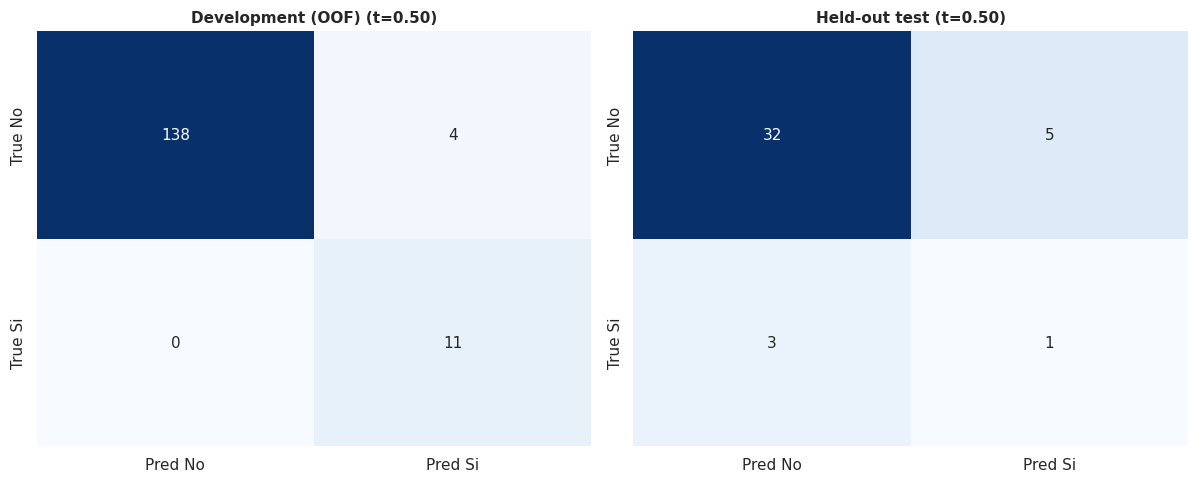

In [ ]:
dev_final = candidates[FINAL_NAME][0]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (split, ys, pred) in zip(ax, [
        ('Development (OOF)', y_dev, (dev_final >= FINAL_THRESHOLD).astype(int)),
        ('Held-out test', y_test, final_test_pred)]):
    cm = confusion_matrix(ys, pred, labels=[0,1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=a,
                xticklabels=['Pred No','Pred Si'], yticklabels=['True No','True Si'])
    a.set_title(f'{split} (t={FINAL_THRESHOLD:.2f})', fontweight='bold', fontsize=10)
plt.tight_layout(); plt.savefig('plot_m5_confusion.png', bbox_inches='tight'); plt.show()

## Appendix A

In [ ]:
RUN_HELDOUT_COST_EXPERIMENT = True   # set False to skip (saves a second CNN training pass)

if RUN_HELDOUT_COST_EXPERIMENT:
    voters_app = ['EfficientNet/M6', 'VGG16', 'MobileNetV2']
    sgkf_full = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

    # --- Deep networks: OOF over ALL 194 images (same configs as the main run) ---
    cnn_oof_full = {}
    for name in voters_app:
        print(f'[full-data] Training {name} across all-data folds...')
        oof_f, _ = cnn_oof_scores(name, df, y_all, groups_all, sgkf_full)
        cnn_oof_full[name] = oof_f
        print(f'  {name}: full-data OOF PR-AUC {average_precision_score(y_all, oof_f):.3f}')

    # --- Classical + tree ensembles on full data (reuse the dev-tuned hyperparameters) ---
    oof_svm_full, _ = oof_proba_classical(build_svm, X_hcq_all, y_all, groups_all, sgkf_full)
    oof_e1_full, _  = oof_proba_classical(rf_factory, X_hcq_all, y_all, groups_all, sgkf_full)
    oof_e2_full, _  = oof_proba_classical(gb_factory, X_hcq_all, y_all, groups_all, sgkf_full)

    # --- Heterogeneous ensembles on full data ---
    Vf = np.column_stack([cnn_oof_full[v] for v in voters_app])
    oof_e3_full = Vf.mean(axis=1)
    voter_thr_full = {v: best_f2_threshold(y_all, cnn_oof_full[v]) for v in voters_app}
    oof_e4_full = np.column_stack([(cnn_oof_full[v] >= voter_thr_full[v]).astype(int)
                                   for v in voters_app]).mean(axis=1)
    Mf = np.column_stack([cnn_oof_full['EfficientNet/M6'], cnn_oof_full['VGG16'],
                          cnn_oof_full['MobileNetV2'], oof_svm_full])
    oof_e5_full = cross_val_predict(meta_factory(), Mf, y_all, groups=groups_all,
                                    cv=sgkf_full, method='predict_proba')[:, 1]

    full_oof = {
        'IND EfficientNet/M6': cnn_oof_full['EfficientNet/M6'],
        'IND VGG16': cnn_oof_full['VGG16'],
        'IND MobileNetV2': cnn_oof_full['MobileNetV2'],
        'IND HCQ+SVM': oof_svm_full,
        'E1: Random forest (bagging)': oof_e1_full,
        'E2: Gradient boosting (boosting)': oof_e2_full,
        'E3: Soft voting': oof_e3_full,
        'E4: Hard voting': oof_e4_full,
        'E5: Stacking': oof_e5_full,
    }
    print('\nFull-data OOF computed for all models.')

[full-data] Training EfficientNet/M6 across all-data folds...
  [EfficientNet/M6] fold 0 done
  [EfficientNet/M6] fold 1 done
  [EfficientNet/M6] fold 2 done
  [EfficientNet/M6] fold 3 done
  [EfficientNet/M6] fold 4 done
  EfficientNet/M6: full-data OOF PR-AUC 0.414
[full-data] Training VGG16 across all-data folds...
  [VGG16] fold 0 done
  [VGG16] fold 1 done
  [VGG16] fold 2 done
  [VGG16] fold 3 done
  [VGG16] fold 4 done
  VGG16: full-data OOF PR-AUC 0.248
[full-data] Training MobileNetV2 across all-data folds...
  [MobileNetV2] fold 0 done
  [MobileNetV2] fold 1 done
  [MobileNetV2] fold 2 done
  [MobileNetV2] fold 3 done
  [MobileNetV2] fold 4 done
  MobileNetV2: full-data OOF PR-AUC 0.198

Full-data OOF computed for all models.


In [ ]:
if RUN_HELDOUT_COST_EXPERIMENT:
    rows = []
    for name, score_full in full_oof.items():
        pr_f = average_precision_score(y_all, score_full)
        _, lo_f, hi_f = bootstrap_ci(y_all, score_full)
        thr_f = 0.5 if name == 'E4: Hard voting' else best_f2_threshold(y_all, score_full)
        rec_f = recall_score(y_all, (score_full >= thr_f).astype(int), pos_label=1, zero_division=0)
        dev_row = comp_df.loc[name]
        rows.append({
            'model': name,
            'PR-AUC dev-only': dev_row['pr_auc'],
            'PR-AUC full-data': pr_f,
            'delta': pr_f - dev_row['pr_auc'],
            'CIw dev-only': dev_row['ci_hi'] - dev_row['ci_lo'],
            'CIw full-data': hi_f - lo_f,
            'recall dev-only': dev_row['recall_Si'],
            'recall full-data': rec_f,
        })
    cost_df = pd.DataFrame(rows).set_index('model').sort_values('PR-AUC full-data', ascending=False)
    print(f'Si cases in OOF evaluation:  full-data = {int(y_all.sum())}   dev-only = {int(y_dev.sum())}')
    print(f'(carving out the test fold removed {int(y_all.sum()) - int(y_dev.sum())} Si cases from the estimate)\n')
    print('Effect of the held-out split (positive delta = full data scores higher):\n')
    print(cost_df.round(3).to_string())
    print(f'\nMean |delta| PR-AUC across models: {cost_df["delta"].abs().mean():.3f}')
    print(f'Mean bootstrap CI width:  dev-only = {cost_df["CIw dev-only"].mean():.3f}   '
          f'full-data = {cost_df["CIw full-data"].mean():.3f}')

Si cases in OOF evaluation:  full-data = 15   dev-only = 11
(carving out the test fold removed 4 Si cases from the estimate)

Effect of the held-out split (positive delta = full data scores higher):

                                  PR-AUC dev-only  PR-AUC full-data  delta  CIw dev-only  CIw full-data  recall dev-only  recall full-data
model                                                                                                                                     
E4: Hard voting                             0.927             0.515 -0.412         0.177          0.457            1.000             0.733
IND EfficientNet/M6                         0.590             0.414 -0.176         0.538          0.490            0.818             0.600
E3: Soft voting                             0.873             0.309 -0.564         0.261          0.371            0.909             0.667
IND VGG16                                   0.531             0.248 -0.283         0.501          0.183  

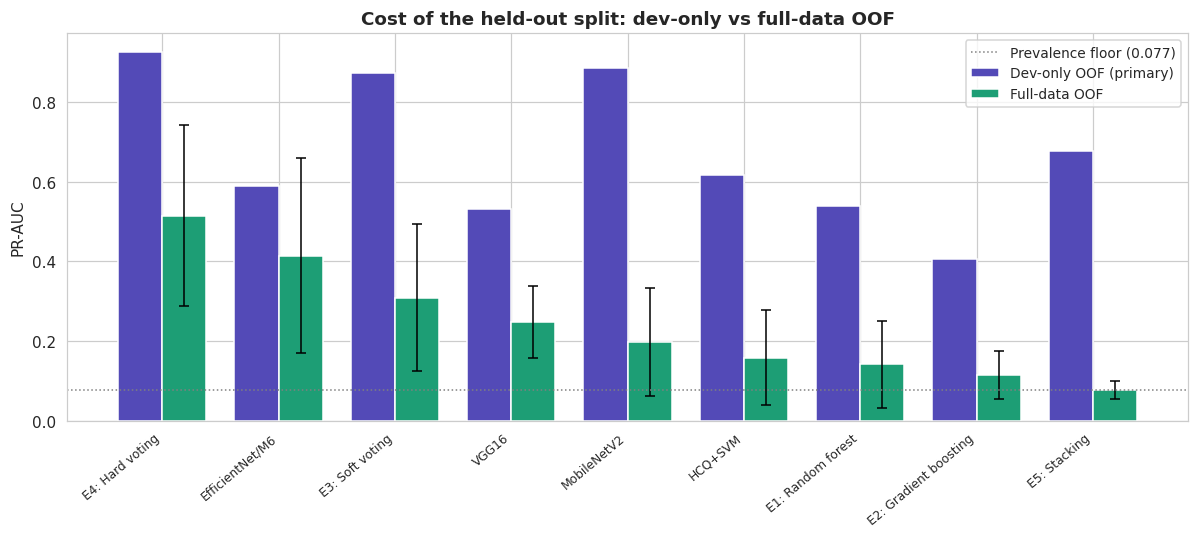

In [ ]:
if RUN_HELDOUT_COST_EXPERIMENT:
    models = cost_df.index.tolist()
    short = [m.replace('IND ', '').replace(' (bagging)', '').replace(' (boosting)', '') for m in models]
    x = np.arange(len(models)); w = 0.38
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(x - w/2, cost_df['PR-AUC dev-only'].values, w, label='Dev-only OOF (primary)', color='#534ab7')
    ax.bar(x + w/2, cost_df['PR-AUC full-data'].values, w, label='Full-data OOF', color='#1d9e75')
    # CI whiskers on the full-data bars
    ax.errorbar(x + w/2, cost_df['PR-AUC full-data'].values,
                yerr=(cost_df['CIw full-data'].values / 2), fmt='none', ecolor='black', capsize=3, lw=1)
    ax.axhline(y_all.mean(), color='gray', ls=':', lw=1, label=f'Prevalence floor ({y_all.mean():.3f})')
    ax.set_xticks(x); ax.set_xticklabels(short, rotation=40, ha='right', fontsize=8)
    ax.set_ylabel('PR-AUC'); ax.set_title('Cost of the held-out split: dev-only vs full-data OOF', fontweight='bold')
    ax.legend(fontsize=9)
    plt.tight_layout(); plt.savefig('plot_m5_heldout_cost.png', bbox_inches='tight', dpi=110); plt.show()

## Appendix B

In [ ]:
# Appendix B: Grad-CAM

import torch.nn.functional as F

# 1) Use the M6 model already fitted on dev; train one if absent.
if 'fitted_models' in globals() and 'EfficientNet/M6' in fitted_models:
    gc_model = fitted_models['EfficientNet/M6']
    print('Using the M6 model already fitted on the development split.')
else:
    print('No fitted M6 found; training one on dev for Grad-CAM...')
    gc_model, _ = cnn_fit_predict('EfficientNet/M6', df_dev, df_dev.iloc[:1])

gc_model.eval()
IMG   = CNN_CFG['EfficientNet/M6']['img']
gc_tf = make_eval_transform(IMG)

# 2) Grad-CAM for one image tensor -> (heatmap in [0,1], P(Si))
def grad_cam(model, x):
    feats = {}
    def hook(m, i, o):
        o.retain_grad(); feats['act'] = o
    h = model._conv_head.register_forward_hook(hook)
    model.zero_grad()
    logit = model(x).squeeze()
    prob  = torch.sigmoid(logit).item()
    logit.backward()
    act  = feats['act']                              # [1, C, h, w]
    w    = act.grad.mean(dim=(2, 3), keepdim=True)   # channel weights
    cam  = F.relu((w * act).sum(dim=1))[0]           # [h, w]
    cam  = cam.detach().cpu().numpy()
    cam  = (cam - cam.min()) / (np.ptp(cam) + 1e-8)
    h.remove()
    return cam, prob

# 3) Pick images: all/most Si cases + a few No for contrast
N_SI_SHOW, N_NO_SHOW = 6, 3
si_imgs = df[df['label_enc'] == 1].reset_index(drop=True).head(N_SI_SHOW)
no_imgs = (df[df['label_enc'] == 0]
           .sample(n=N_NO_SHOW, random_state=RANDOM_STATE)
           .reset_index(drop=True))
show = pd.concat([si_imgs, no_imgs], ignore_index=True)

# 4) Plot original OCT + Grad-CAM overlay
n, cols = len(show), 3
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4.2*cols, 4.2*rows))
axes = np.array(axes).reshape(-1)
for ax in axes:
    ax.axis('off')
for j in range(n):
    row = show.iloc[j]
    pil = Image.open(row['filepath']).convert('RGB').resize((IMG, IMG))
    x   = gc_tf(pil).unsqueeze(0).to(DEVICE)
    cam, prob = grad_cam(gc_model, x)
    cam_up = np.array(Image.fromarray((cam*255).astype('uint8')).resize((IMG, IMG)))
    true = 'Si' if row['label_enc'] == 1 else 'No'
    axes[j].imshow(pil)
    axes[j].imshow(cam_up, cmap='jet', alpha=0.45)
    axes[j].set_title(f'true={true} · p(Si)={prob:.2f}', fontsize=10)
plt.tight_layout()
plt.savefig('plot_appendixB_gradcam.png', bbox_inches='tight', dpi=110)
plt.show()

Output hidden; open in https://colab.research.google.com to view.

## Appendix C: SVM in voting

E3 and E4 evaluated soft and hard voting using EfficientNet/M6, VGG16 and MobileNetV2 as the voters. Additionaly, we ran another comparison analysis of these ensemble ML techniques with SVM (instead of MobileNetV2) as one of the voters. These results are separated from the previous comparison because these meta-models were evaluated with the held-out test set, not with the development set as done earlier.

In [ ]:
def calcular_soft_voting(lista_probabilidades, umbral=0.5):
    """
    Calcultaes  Soft Voting (probability's mean).

    Returns:
    - probs_soft: arrengements with the average probabilities.
    - preds_soft: arrengement with the binary output.
    """

    matriz_probabilidades = np.column_stack(lista_probabilidades)

    probs_soft = np.mean(matriz_probabilidades, axis=1)
    preds_soft = (probs_soft >= umbral).astype(int)

    return probs_soft, preds_soft

In [ ]:
def calcular_hard_voting(lista_probabilidades, umbral_individual=0.5, votos_minimos=None):
    """
    Calcultaes Hard Voting (democracy vote) transforming probablities into a binray output.

    Returns:
    - preds_hard:arrengement with the final predictions.
    """
    matriz_probabilidades = np.column_stack(lista_probabilidades)
    num_modelos = matriz_probabilidades.shape[1]

    # Individual model's vote
    votos_individuales = (matriz_probabilidades >= umbral_individual).astype(int)

    # Sum up the votes
    total_votos_por_paciente = np.sum(votos_individuales, axis=1)

    if votos_minimos is None:
        votos_minimos = (num_modelos // 2) + 1


    preds_hard = (total_votos_por_paciente >= votos_minimos).astype(int)

    return preds_hard

In [ ]:
# Entrenamiento SVM
print(" Generando predicciones SVM: ")

# Predicciones OOF
# oof_svm, _ = oof_proba_classical(build_svm, X_hcq_dev, y_dev, groups_dev, sgkf)

svm_final = build_svm().fit(X_hcq_dev, y_dev)
probs_svm_test = svm_final.predict_proba(X_hcq_test)[:, 1]

In [ ]:
# Entrenamiento M6 (HCQuery Full FT )
print("Generando predicciones M6: ")

def m6_oof_scores(frame, y_arr, groups_arr, cv, epochs=15, lr=1e-5,
                  weight_decay=1e-3, patience=4):
    '''Leakage-safe OOF probabilities for M6 over a patient-grouped CV.'''
    train_tf = make_train_transform(IMG_SIZE_HCQ)
    eval_tf = make_eval_transform(IMG_SIZE_HCQ)
    oof = np.zeros(len(frame), dtype=float)
    t0 = time.time()
    for k, (tr, va) in enumerate(cv.split(frame, y_arr, groups_arr)):
        tr_frame = frame.iloc[tr].reset_index(drop=True)
        va_frame = frame.iloc[va].reset_index(drop=True)
        tr_loader = DataLoader(OCTDatasetRGB(tr_frame, train_tf),
                               batch_size=16, sampler=make_balanced_sampler(tr_frame))
        va_loader = DataLoader(OCTDatasetRGB(va_frame, eval_tf),
                               batch_size=16, shuffle=False)
        model = train_cnn(build_m6_full_finetune(), tr_loader, va_loader,
                          epochs=epochs, lr=lr, weight_decay=weight_decay, patience=patience)
        oof[va] = predict_cnn_scores(model, va_loader)
        print(f'  fold {k} done')
    return oof, time.time() - t0

def m6_fit_predict(train_frame, predict_frame, val_frac=0.15,
                   epochs=15, lr=1e-5, weight_decay=1e-3, patience=4):
    '''Fit M6 on train_frame (with an internal grouped val for early stopping)
       and return probabilities on predict_frame. Used for the test set.'''
    train_tf = make_train_transform(IMG_SIZE_HCQ)
    eval_tf = make_eval_transform(IMG_SIZE_HCQ)
    inner = StratifiedGroupKFold(n_splits=max(2, int(round(1/val_frac))),
                                 shuffle=True, random_state=RANDOM_STATE)
    yi = train_frame['label_enc'].values
    gi = train_frame['patient_id'].values
    tr, va = next(inner.split(train_frame, yi, gi))
    tr_frame = train_frame.iloc[tr].reset_index(drop=True)
    va_frame = train_frame.iloc[va].reset_index(drop=True)
    tr_loader = DataLoader(OCTDatasetRGB(tr_frame, train_tf),
                           batch_size=16, sampler=make_balanced_sampler(tr_frame))
    va_loader = DataLoader(OCTDatasetRGB(va_frame, eval_tf),
                           batch_size=16, shuffle=False)
    model = train_cnn(build_m6_full_finetune(), tr_loader, va_loader,
                      epochs=epochs, lr=lr, weight_decay=weight_decay, patience=patience)
    pred_loader = DataLoader(OCTDatasetRGB(predict_frame, eval_tf),
                             batch_size=16, shuffle=False)
    return model, predict_cnn_scores(model, pred_loader)

print('Fine-tune infrastructure ready (parametric).')

# Predicciones OOF
oof_m6, _ = m6_oof_scores(df_dev, y_dev, groups_dev, sgkf)

_, probs_m6_test = m6_fit_predict(df_dev, df_test)

In [ ]:
# Entrenamiento VGG16 PARTIAL FT

print("Entrenando VGG16 (Partial FT): ")

def build_vgg16_partial_ft():
    weights = tv_models.VGG16_Weights.DEFAULT
    model = tv_models.vgg16(weights=weights)
    for param in model.parameters():
        param.requires_grad = False
    for param in model.features[24:].parameters():
        param.requires_grad = True
    in_feats = model.classifier[6].in_features
    model.classifier[6] = nn.Linear(in_feats, 1)
    for param in model.classifier.parameters():
        param.requires_grad = True
    return model.to(DEVICE)

def vgg_fit_predict(train_frame, predict_frame, val_frac=0.15, epochs=15):
    train_tf = make_train_transform(224) # VGG16 usa 224
    eval_tf = make_eval_transform(224)
    inner = StratifiedGroupKFold(n_splits=max(2, int(round(1/val_frac))), shuffle=True, random_state=RANDOM_STATE)
    yi, gi = train_frame['label_enc'].values, train_frame['patient_id'].values
    tr, va = next(inner.split(train_frame, yi, gi))

    tr_loader = DataLoader(OCTDatasetRGB(train_frame.iloc[tr], train_tf), batch_size=16, sampler=make_balanced_sampler(train_frame.iloc[tr]))
    va_loader = DataLoader(OCTDatasetRGB(train_frame.iloc[va], eval_tf), batch_size=16, shuffle=False)

    model = train_cnn(build_vgg16_partial_ft(), tr_loader, va_loader, epochs=epochs)
    pred_loader = DataLoader(OCTDatasetRGB(predict_frame, eval_tf), batch_size=16, shuffle=False)
    return model, predict_cnn_scores(model, pred_loader)

# Predicciones OOF
_, probs_vgg_test = vgg_fit_predict(df_dev, df_test)

In [ ]:
lista_modelos_test = [probs_svm_test, probs_m6_test, probs_vgg_test]

#Soft voting
probs_soft_test, preds_soft_test = calcular_soft_voting(lista_modelos_test, umbral=0.5)

# Hard voting
preds_hard_test = calcular_hard_voting(lista_modelos_test, umbral_individual=0.5, votos_minimos=2)

# Ensamble
X_ensamble_dev = np.column_stack((oof_svm, oof_m6))
meta_learner = LogisticRegression(C=1.0, class_weight='balanced', random_state=RANDOM_STATE)
meta_learner.fit(X_ensamble_dev, y_dev)

# Predicciones
X_test_para_stacking = np.column_stack((probs_svm_test, probs_m6_test))
probs_stack_test = meta_learner.predict_proba(X_test_para_stacking)[:, 1]
preds_stack_test = meta_learner.predict(X_test_para_stacking)

# Resultados

def print_resultados_finales(nombre, preds, probs):
    # Evaluamos contra y_test
    pr_auc = average_precision_score(y_test, probs)
    recall = recall_score(y_test, preds, zero_division=0)
    f2 = fbeta_score(y_test, preds, beta=2, zero_division=0)
    print(f"{nombre:<25} | PR-AUC: {pr_auc:.3f} | Recall: {recall:.3f} | F2-Score: {f2:.3f}")

print("\n" + "="*65)
print(" Resultados finales: ")
print("="*65)
print_resultados_finales("Modelo SVM: ", (probs_svm_test > 0.5).astype(int), probs_svm_test)
print_resultados_finales("Modelo M6 (HCQ): ", (probs_m6_test > 0.5).astype(int), probs_m6_test)
print_resultados_finales("Modelo VGG16: ", (probs_vgg_test > 0.5).astype(int), probs_vgg_test)
print("-" * 65)
print_resultados_finales("Soft Voting:", preds_soft_test, probs_soft_test)
print_resultados_finales("Hard Voting: ", preds_hard_test, preds_hard_test) # Hard usa preds como probs para la métrica
print_resultados_finales("Stacking:", preds_stack_test, probs_stack_test)
print("="*65)